# Lab – Nhận diện cảm xúc khuôn mặt (FER-2013)
**Sinh viên:** Trần Thanh Gia Khang – CE200292 – AI2001

Notebook huấn luyện và đánh giá **M1** (CNN tự thiết kế) và **M2** (MobileNetV2 transfer learning).
Chạy trên Google Colab (Runtime → Change runtime type → GPU). Notebook cần thư mục project
(chứa `src/`, `notebooks/`): hoặc đã có trong Colab/Drive, hoặc cell đầu sẽ hỏi upload file zip.
Chạy **Run all** và lưu lại notebook *còn output*.

In [1]:
import copy, json, os, random, subprocess, sys, time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T

def find_root():
    """Tìm thư mục gốc project (chứa src/model.py): cwd, thư mục cha, /content, Google Drive.
    Nếu không thấy và đang ở Colab thì yêu cầu upload file .zip của project."""
    here = Path.cwd()
    cands = [here, here.parent] + sorted(Path("/content").glob("*")) \
        + sorted(Path("/content/drive/MyDrive").glob("*")) + sorted(Path("/content/drive/MyDrive").glob("*/*"))
    for c in cands:
        if (c / "src" / "model.py").exists():
            return c
    try:
        from google.colab import files
        print("Không thấy thư mục project -> hãy chọn file CE200292_TranThanhGiaKhang_Lab2.zip để upload")
        files.upload()
        for z in Path("/content").glob("*.zip"):
            subprocess.run(["unzip", "-oq", str(z), "-d", "/content"], check=True)
        for c in Path("/content").glob("*"):
            if (c / "src" / "model.py").exists():
                return c
    except ImportError:
        pass
    raise FileNotFoundError("Không tìm thấy src/model.py. Hãy chạy notebook từ thư mục project "
                            "(chứa src/, notebooks/) hoặc upload file zip của project lên Colab.")


ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
from model import build_model, count_params      # định nghĩa mô hình (src/model.py)
from predict import INPUT, preprocess            # tiền xử lý DÙNG CHUNG với app realtime

# ---- Tham số (chỉnh ở đây) ----
DATA_DIR = None          # thư mục chứa train/ và test/ ; None = tự tải FER-2013 từ Kaggle (Colab)
EPOCHS_M1 = 40
LR_M1 = 5e-4            # lr của M1 (1e-3 từng làm mạng bị 'chết': loss kẹt ở ln7)
EPOCHS_M2_HEAD, EPOCHS_M2_FT = 3, 20   # M2: 3 epoch chỉ train lớp cuối, rồi 20 epoch fine-tune toàn mạng
BATCH = 128
RUN_ABLATION = True      # so sánh M1 có / không class weight (để kiểm tra class weight có thực sự giúp không)
SEED = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT_W, OUT_R = ROOT / "weights", ROOT / "report_assets"
OUT_W.mkdir(exist_ok=True); OUT_R.mkdir(exist_ok=True)
print("Device:", DEVICE, "| ROOT:", ROOT)

Không thấy thư mục project -> hãy chọn file CE200292_TranThanhGiaKhang_Lab1.zip để upload


Saving CE200292_TranThanhGiaKhang_Lab2.zip to CE200292_TranThanhGiaKhang_Lab2.zip
Device: cuda | ROOT: /content/CE200292_TranThanhGiaKhang_Lab2


## 1. Dữ liệu
Nguồn: **FER-2013** (Kaggle `msambare/fer2013`), ảnh xám 48×48, 7 lớp. Thư mục `train/` (~28.7k ảnh) và
`test/` (~7.2k ảnh). Tập validation được tách 10% (stratified) từ `train/`; `test/` chỉ dùng để đánh giá cuối.

In [2]:
if DATA_DIR is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("msambare/fer2013")
DATA_DIR = Path(DATA_DIR)
TRAIN_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "test"
CLASSES = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())   # thứ tự alphabet
print(CLASSES)


def list_images(root):
    paths, labels = [], []
    for i, c in enumerate(CLASSES):
        for p in sorted((root / c).glob("*")):
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                paths.append(p); labels.append(i)
    return paths, np.array(labels)


all_paths, all_y = list_images(TRAIN_DIR)
te_paths, te_y = list_images(TEST_DIR)
tr_paths, va_paths, tr_y, va_y = train_test_split(all_paths, all_y, test_size=0.1, stratify=all_y, random_state=SEED)
print(f"train={len(tr_paths)}  val={len(va_paths)}  test={len(te_paths)}  (tổng {len(all_paths) + len(te_paths)} ảnh)")

Using Colab cache for faster access to the 'fer2013' dataset.
['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
train=25838  val=2871  test=7178  (tổng 35887 ảnh)


### Phân bố lớp và xử lý mất cân bằng
FER-2013 mất cân bằng mạnh (Disgust rất ít). Biện pháp: **class weight** (w_c = N / (K·n_c)) trong hàm loss
+ **augmentation** (lật ngang, xoay/dịch/co giãn nhẹ, đổi độ sáng/tương phản) chỉ áp dụng cho tập train.

angry     train= 3596 (13.9%)  weight=1.03  test=958
disgust   train=  392 ( 1.5%)  weight=9.42  test=111
fear      train= 3687 (14.3%)  weight=1.00  test=1024
happy     train= 6493 (25.1%)  weight=0.57  test=1774
neutral   train= 4469 (17.3%)  weight=0.83  test=1233
sad       train= 4347 (16.8%)  weight=0.85  test=1247
surprise  train= 2854 (11.0%)  weight=1.29  test=831


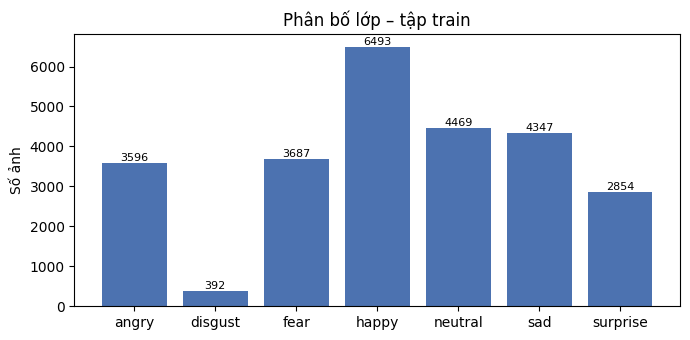

In [3]:
counts = np.bincount(tr_y, minlength=len(CLASSES))
class_w = torch.tensor(len(tr_y) / (len(CLASSES) * counts), dtype=torch.float32)
for c, n, w in zip(CLASSES, counts, class_w):
    print(f"{c:9s} train={n:5d} ({n / len(tr_y) * 100:4.1f}%)  weight={w:.2f}  test={np.sum(te_y == CLASSES.index(c))}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(CLASSES, counts, color="#4C72B0")
for i, n in enumerate(counts):
    ax.text(i, n, str(n), ha="center", va="bottom", fontsize=8)
ax.set_title("Phân bố lớp – tập train"); ax.set_ylabel("Số ảnh")
fig.tight_layout(); fig.savefig(OUT_R / "class_distribution.png", dpi=150); plt.show()

In [4]:
AUG = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3),
])


class FERDataset(Dataset):
    """Nạp toàn bộ ảnh vào RAM (ảnh 48x48 nên rất nhẹ). Augment (nếu có) rồi gọi preprocess() dùng chung với app."""

    def __init__(self, paths, labels, kind, augment=False):
        self.imgs = [Image.open(p).convert("L") for p in paths]
        self.labels, self.kind, self.augment = labels, kind, augment

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        img = AUG(self.imgs[i]) if self.augment else self.imgs[i]
        return preprocess(np.array(img), self.kind), int(self.labels[i])


def make_loaders(kind):
    mk = lambda p, y, aug, shuf: DataLoader(FERDataset(p, y, kind, aug), batch_size=BATCH, shuffle=shuf, num_workers=2)
    return mk(tr_paths, tr_y, True, True), mk(va_paths, va_y, False, False), mk(te_paths, te_y, False, False)

## 2. Huấn luyện
Optimizer AdamW + CosineAnnealingLR; chọn checkpoint có **val accuracy** cao nhất (không dùng test để chọn model).

In [5]:
def run_epoch(model, loader, criterion, opt=None):
    train = opt is not None
    model.train(train)
    loss_sum = correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = criterion(out, y)
            if train:
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)   # chặn gradient bùng nổ
                opt.step()
            loss_sum += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
    return loss_sum / n, correct / n


def train_model(kind, phases, weighted=True, pretrained=True):
    """phases: list (số epoch, learning rate, freeze_backbone). Trả về (model tốt nhất, history)."""
    model = build_model(kind, len(CLASSES), pretrained).to(DEVICE)
    tr, va, _ = make_loaders(kind)
    criterion = nn.CrossEntropyLoss(weight=class_w.to(DEVICE) if weighted else None)
    hist = {k: [] for k in ("train_loss", "val_loss", "train_acc", "val_acc")}
    best = {"acc": -1, "state": None}
    for epochs, lr, freeze in phases:
        if kind == "transfer":
            for p in model.features.parameters():
                p.requires_grad = not freeze
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        for ep in range(epochs):
            t0 = time.time()
            tl, ta = run_epoch(model, tr, criterion, opt)
            vl, vacc = run_epoch(model, va, criterion)
            sched.step()
            for k, v in zip(hist, (tl, vl, ta, vacc)):
                hist[k].append(v)
            if kind == "cnn" and len(hist["val_acc"]) == 5 and vacc < 0.30:   # ~25% = đoán theo lớp đông nhất
                raise RuntimeError(f"M1 không học được (val acc {vacc:.3f} sau 5 epoch). "
                                   "Giảm LR_M1 (vd. 2e-4) rồi chạy lại cell này.")
            if vacc > best["acc"]:
                best = {"acc": vacc, "state": copy.deepcopy(model.state_dict())}
            print(f"[{kind}{' (freeze)' if freeze else ''}] ep {len(hist['val_acc']):2d} "
                  f"loss {tl:.3f}/{vl:.3f}  acc {ta:.3f}/{vacc:.3f}  ({time.time() - t0:.0f}s)")
    model.load_state_dict(best["state"])
    print(f"-> best val acc = {best['acc']:.4f}")
    return model, hist

### M1 – CNN tự thiết kế (Conv–BN–ReLU–Pool–Dropout)

In [6]:
m1, h1 = train_model("cnn", [(EPOCHS_M1, LR_M1, False)], weighted=True)

[cnn] ep  1 loss 1.934/1.746  acc 0.212/0.288  (17s)
[cnn] ep  2 loss 1.735/1.502  acc 0.326/0.420  (15s)
[cnn] ep  3 loss 1.547/1.382  acc 0.404/0.472  (16s)
[cnn] ep  4 loss 1.475/1.388  acc 0.435/0.499  (15s)
[cnn] ep  5 loss 1.408/1.331  acc 0.461/0.521  (15s)
[cnn] ep  6 loss 1.351/1.290  acc 0.480/0.522  (15s)
[cnn] ep  7 loss 1.328/1.259  acc 0.492/0.520  (15s)
[cnn] ep  8 loss 1.295/1.220  acc 0.498/0.552  (15s)
[cnn] ep  9 loss 1.279/1.265  acc 0.510/0.572  (15s)
[cnn] ep 10 loss 1.245/1.180  acc 0.521/0.584  (15s)
[cnn] ep 11 loss 1.228/1.189  acc 0.530/0.551  (15s)
[cnn] ep 12 loss 1.212/1.158  acc 0.534/0.576  (15s)
[cnn] ep 13 loss 1.198/1.125  acc 0.537/0.574  (15s)
[cnn] ep 14 loss 1.182/1.092  acc 0.546/0.580  (15s)
[cnn] ep 15 loss 1.159/1.118  acc 0.550/0.606  (15s)
[cnn] ep 16 loss 1.151/1.108  acc 0.556/0.608  (15s)
[cnn] ep 17 loss 1.137/1.102  acc 0.561/0.607  (15s)
[cnn] ep 18 loss 1.126/1.073  acc 0.565/0.606  (15s)
[cnn] ep 19 loss 1.109/1.087  acc 0.567/0.611 

### M2 – Transfer learning MobileNetV2 (ImageNet), ảnh vào 96×96×3
Giai đoạn 1: đóng băng backbone, chỉ train lớp phân loại mới. Giai đoạn 2: mở khoá toàn mạng, lr nhỏ hơn.

In [7]:
m2, h2 = train_model("transfer", [(EPOCHS_M2_HEAD, 1e-3, True), (EPOCHS_M2_FT, 3e-4, False)], weighted=True)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 96.2MB/s]


[transfer (freeze)] ep  1 loss 1.860/1.792  acc 0.277/0.350  (15s)
[transfer (freeze)] ep  2 loss 1.798/1.734  acc 0.307/0.350  (15s)
[transfer (freeze)] ep  3 loss 1.747/1.729  acc 0.318/0.373  (15s)
[transfer] ep  4 loss 1.534/1.270  acc 0.433/0.509  (25s)
[transfer] ep  5 loss 1.276/1.151  acc 0.522/0.555  (24s)
[transfer] ep  6 loss 1.163/1.146  acc 0.554/0.596  (25s)
[transfer] ep  7 loss 1.102/1.107  acc 0.578/0.617  (25s)
[transfer] ep  8 loss 1.033/1.110  acc 0.601/0.616  (25s)
[transfer] ep  9 loss 0.979/1.082  acc 0.616/0.634  (25s)
[transfer] ep 10 loss 0.952/1.086  acc 0.628/0.633  (25s)
[transfer] ep 11 loss 0.903/1.098  acc 0.641/0.648  (25s)
[transfer] ep 12 loss 0.877/1.095  acc 0.652/0.645  (25s)
[transfer] ep 13 loss 0.832/1.076  acc 0.664/0.646  (25s)
[transfer] ep 14 loss 0.803/1.103  acc 0.677/0.659  (25s)
[transfer] ep 15 loss 0.756/1.156  acc 0.691/0.664  (25s)
[transfer] ep 16 loss 0.727/1.189  acc 0.699/0.658  (25s)
[transfer] ep 17 loss 0.703/1.211  acc 0.712/

## 3. Đánh giá trên tập test

In [8]:
@torch.inference_mode()
def predict_loader(model, loader):
    model.eval()
    ys, probs = [], []
    for x, y in loader:
        probs.append(torch.softmax(model(x.to(DEVICE)), 1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(probs).numpy()


def evaluate(model, kind):
    _, _, te = make_loaders(kind)
    y, p = predict_loader(model, te)
    pred = p.argmax(1)
    return {"y": y, "probs": p, "pred": pred, "acc": accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, average="macro", zero_division=0)}


@torch.inference_mode()
def bench_fps(model, kind, n=200):
    """FPS suy luận trên CPU cho 1 khuôn mặt (batch=1). Số đo thật nằm ở FPS của app trên laptop của bạn."""
    m = copy.deepcopy(model).cpu().eval()
    x = preprocess(np.random.randint(0, 255, (48, 48), dtype=np.uint8), kind)[None]
    for _ in range(10):
        m(x)
    t0 = time.perf_counter()
    for _ in range(n):
        m(x)
    return n / (time.perf_counter() - t0)


R1, R2 = evaluate(m1, "cnn"), evaluate(m2, "transfer")
for name, R in (("M1 cnn", R1), ("M2 transfer", R2)):
    print(f"\n===== {name}: acc={R['acc']:.4f}  macro-F1={R['macro_f1']:.4f}")
    print(classification_report(R["y"], R["pred"], target_names=CLASSES, digits=3, zero_division=0))


===== M1 cnn: acc=0.6450  macro-F1=0.6081
              precision    recall  f1-score   support

       angry      0.568     0.581     0.575       958
     disgust      0.390     0.766     0.517       111
        fear      0.505     0.344     0.409      1024
       happy      0.883     0.844     0.863      1774
     neutral      0.573     0.663     0.614      1233
         sad      0.538     0.488     0.512      1247
    surprise      0.694     0.857     0.767       831

    accuracy                          0.645      7178
   macro avg      0.593     0.649     0.608      7178
weighted avg      0.644     0.645     0.640      7178


===== M2 transfer: acc=0.6668  macro-F1=0.6524
              precision    recall  f1-score   support

       angry      0.536     0.644     0.585       958
     disgust      0.688     0.676     0.682       111
        fear      0.531     0.425     0.472      1024
       happy      0.882     0.846     0.864      1774
     neutral      0.612     0.689     0.6

### M3 – So sánh M1 và M2

In [9]:
rows = []
for name, kind, model, R in (("M1 – CNN tự thiết kế", "cnn", m1, R1), ("M2 – MobileNetV2", "transfer", m2, R2)):
    rows.append({"Mô hình": name, "Accuracy": R["acc"], "Macro F1": R["macro_f1"],
                 "Tham số": count_params(model), "FPS (CPU, batch=1)": bench_fps(model, kind)})
print(f"{'Mô hình':24s} {'Accuracy':>9s} {'MacroF1':>8s} {'Tham số':>11s} {'FPS':>7s}")
for r in rows:
    print(f"{r['Mô hình']:24s} {r['Accuracy'] * 100:8.2f}% {r['Macro F1']:8.4f} {r['Tham số']:11,d} {r['FPS (CPU, batch=1)']:7.1f}")
print(f"\nYêu cầu: M1 ≥ 60% -> {'ĐẠT' if R1['acc'] >= 0.60 else 'CHƯA ĐẠT'} | M2 ≥ 65% -> {'ĐẠT' if R2['acc'] >= 0.65 else 'CHƯA ĐẠT'}")

Mô hình                   Accuracy  MacroF1     Tham số     FPS
M1 – CNN tự thiết kế        64.50%   0.6081   3,507,015    95.9
M2 – MobileNetV2            66.68%   0.6524   2,232,839   108.5

Yêu cầu: M1 ≥ 60% -> ĐẠT | M2 ≥ 65% -> ĐẠT


**Nhận xét M3.** Cả hai mô hình đạt ngưỡng tối thiểu của đề (M1 ≥ 60%, M2 ≥ 65%); M2 vượt ngưỡng 65% khoảng 1,7 điểm. M2 (MobileNetV2) hơn M1 khoảng 2,2 điểm accuracy
(66,68% so với 64,50%) và hơn 4,4 điểm macro F1 (0,652 so với 0,608), đồng thời ít tham số hơn (2,23M so với 3,51M, ít hơn khoảng 36%).
Khoảng cách macro F1 lớn hơn khoảng cách accuracy chủ yếu nhờ lớp *disgust* (F1 0,682 ở M2 so với 0,517 ở M1), lớp chỉ có 111 ảnh test; ở M1 precision của disgust chỉ 0,39.
FPS ở bảng chỉ đo riêng bước phân loại một khuôn mặt (batch = 1) trên CPU của Colab nên chỉ dùng để so sánh tương đối giữa hai mô hình; FPS của cả pipeline
(đọc luồng + phát hiện mặt + phân loại) được đo riêng bằng `src/app.py` trên laptop khi demo.

### Ablation: class weight có giúp không? (M1)

In [10]:
ablation = None
if RUN_ABLATION:
    m1_nw, _ = train_model("cnn", [(EPOCHS_M1, LR_M1, False)], weighted=False)
    Rnw = evaluate(m1_nw, "cnn")
    f1_each = lambda R: f1_score(R["y"], R["pred"], average=None, zero_division=0)
    d = CLASSES.index("disgust")
    ablation = {"with_weight": {"acc": R1["acc"], "macro_f1": R1["macro_f1"], "f1_disgust": f1_each(R1)[d]},
                "no_weight": {"acc": Rnw["acc"], "macro_f1": Rnw["macro_f1"], "f1_disgust": f1_each(Rnw)[d]}}
    for k, v in ablation.items():
        print(f"{k:12s} acc={v['acc'] * 100:.2f}%  macroF1={v['macro_f1']:.4f}  F1(disgust)={v['f1_disgust']:.3f}")

[cnn] ep  1 loss 1.723/1.482  acc 0.313/0.419  (16s)
[cnn] ep  2 loss 1.443/1.272  acc 0.443/0.514  (16s)
[cnn] ep  3 loss 1.325/1.194  acc 0.496/0.546  (15s)
[cnn] ep  4 loss 1.255/1.142  acc 0.520/0.568  (14s)
[cnn] ep  5 loss 1.218/1.128  acc 0.537/0.563  (14s)
[cnn] ep  6 loss 1.188/1.100  acc 0.544/0.582  (15s)
[cnn] ep  7 loss 1.163/1.047  acc 0.560/0.610  (15s)
[cnn] ep  8 loss 1.144/1.114  acc 0.563/0.586  (15s)
[cnn] ep  9 loss 1.130/1.017  acc 0.574/0.608  (15s)
[cnn] ep 10 loss 1.111/1.007  acc 0.577/0.620  (15s)
[cnn] ep 11 loss 1.089/0.988  acc 0.588/0.630  (15s)
[cnn] ep 12 loss 1.080/0.980  acc 0.588/0.625  (15s)
[cnn] ep 13 loss 1.070/1.006  acc 0.595/0.621  (15s)
[cnn] ep 14 loss 1.057/1.018  acc 0.600/0.616  (15s)
[cnn] ep 15 loss 1.045/0.981  acc 0.606/0.633  (15s)
[cnn] ep 16 loss 1.033/0.951  acc 0.612/0.646  (15s)
[cnn] ep 17 loss 1.025/0.955  acc 0.612/0.638  (15s)
[cnn] ep 18 loss 1.013/0.928  acc 0.619/0.653  (15s)
[cnn] ep 19 loss 1.007/0.945  acc 0.623/0.648 

**Kết luận ablation (class weight).** Trong lần chạy này, M1 *không* dùng class weight cho kết quả tốt hơn về tổng thể: accuracy 67,36% so với 64,50%
và macro F1 0,632 so với 0,608. Riêng lớp disgust thì ngược lại: có weight cho F1 0,517, không weight cho F1 0,497. Trọng số lớn (disgust ≈ 9,4) kéo recall của disgust lên cao (0,77)
nhưng precision thấp (0,39) vì mô hình dự đoán disgust quá nhiều, đồng thời làm giảm độ chính xác ở các lớp lớn.
Qua hai lần chạy, xu hướng ở accuracy và macro F1 giống nhau (không weight tốt hơn khoảng 3 điểm accuracy), còn chênh lệch F1 của disgust đổi dấu giữa hai lần:
lớp này chỉ có 111 ảnh test nên số liệu rất không ổn định. Trọng số `weights/cnn.pt` dùng ở app và báo cáo là bản **có class weight** (biến `m1`);
bản không weight (`m1_nw`) chỉ dùng cho ablation và không được lưu.
Hướng cải thiện: dùng trọng số giảm nhẹ (ví dụ căn bậc hai của trọng số hiện tại) hoặc kết hợp label smoothing.
Lưu ý M1 không weight (67,36%) có accuracy cao hơn M2 (66,68%); M2 vẫn nhỉnh hơn về macro F1 (0,652 so với 0,632), số tham số và FPS.

### M4 – Confusion matrix và phân tích lỗi

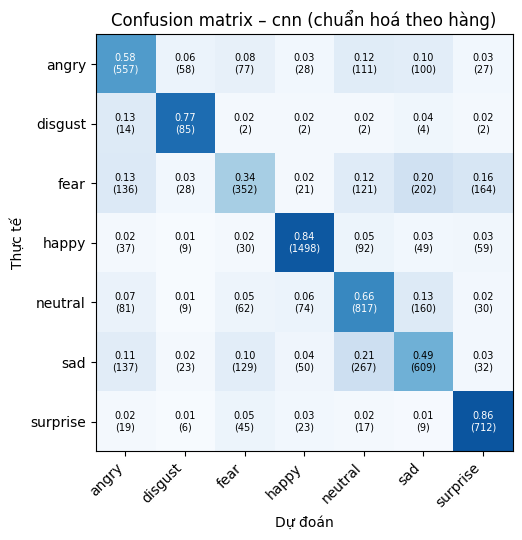

Các cặp nhầm lẫn nhiều nhất của cnn:
  sad -> neutral: 267 ảnh
  fear -> sad: 202 ảnh
  fear -> surprise: 164 ảnh
  neutral -> sad: 160 ảnh
  sad -> angry: 137 ảnh


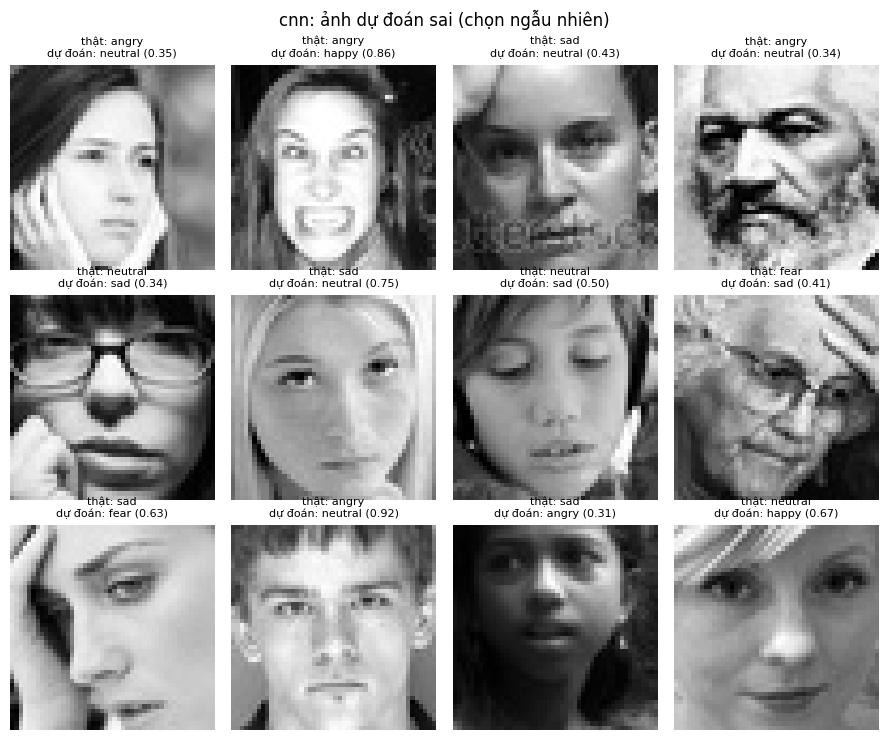

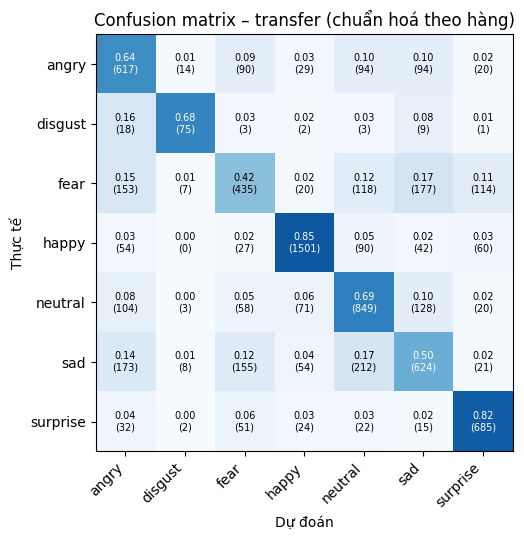

Các cặp nhầm lẫn nhiều nhất của transfer:
  sad -> neutral: 212 ảnh
  fear -> sad: 177 ảnh
  sad -> angry: 173 ảnh
  sad -> fear: 155 ảnh
  fear -> angry: 153 ảnh


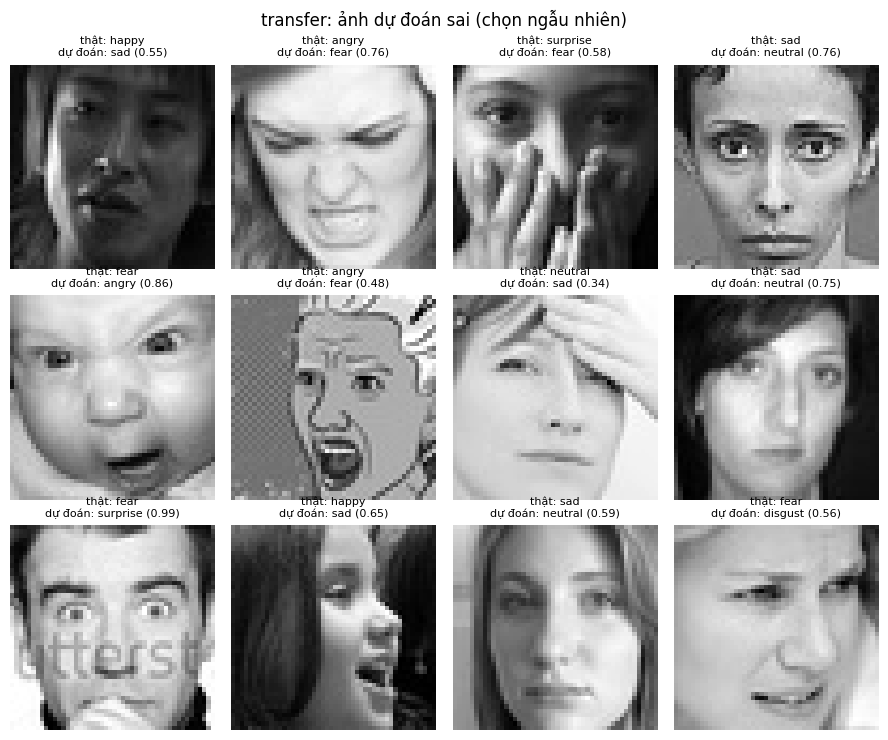

In [11]:
def plot_cm(R, name):
    cm = confusion_matrix(R["y"], R["pred"])
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right"); ax.set_yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế"); ax.set_title(f"Confusion matrix – {name} (chuẩn hoá theo hàng)")
    fig.tight_layout(); fig.savefig(OUT_R / f"cm_{name}.png", dpi=150); plt.show()
    return cm


def show_errors(R, name, n=12):
    wrong = np.where(R["pred"] != R["y"])[0]
    rng = np.random.RandomState(SEED)
    pick = rng.choice(wrong, size=min(n, len(wrong)), replace=False)
    fig, axes = plt.subplots(3, 4, figsize=(9, 7.5))
    for ax, i in zip(axes.ravel(), pick):
        ax.imshow(Image.open(te_paths[i]).convert("L"), cmap="gray"); ax.axis("off")
        ax.set_title(f"thật: {CLASSES[R['y'][i]]}\ndự đoán: {CLASSES[R['pred'][i]]} ({R['probs'][i].max():.2f})", fontsize=8)
    fig.suptitle(f"{name}: ảnh dự đoán sai (chọn ngẫu nhiên)"); fig.tight_layout()
    fig.savefig(OUT_R / f"errors_{name}.png", dpi=150); plt.show()


def top_confusions(cm, k=5):
    off = [(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j]
    for n, a, b in sorted(off, reverse=True)[:k]:
        print(f"  {a} -> {b}: {n} ảnh")


for name, R in (("cnn", R1), ("transfer", R2)):
    cm = plot_cm(R, name)
    print(f"Các cặp nhầm lẫn nhiều nhất của {name}:"); top_confusions(cm)
    show_errors(R, name)

**Nhận xét M4 – phân tích lỗi** (theo lần chạy này; 12 ảnh sai mỗi mô hình được chọn ngẫu nhiên với seed 42).

*Các cặp nhầm lẫn nhiều nhất.* M1: sad→neutral (267), fear→sad (202), fear→surprise (164), neutral→sad (160), sad→angry (137).
M2: sad→neutral (212), fear→sad (177), sad→angry (173), sad→fear (155), fear→angry (153). Hai mô hình nhầm giống nhau ở nhóm
*sad – neutral – fear*, và *fear* là lớp khó nhất (recall 0,34 ở M1, 0,43 ở M2), tiếp theo là *sad* (recall ≈ 0,49–0,50). Nguyên nhân thường là biểu cảm nhẹ, dễ lẫn giữa các lớp gần nhau.

*Nhận xét từ các ảnh sai (nguyên nhân thường gặp):*
1. **Nhãn mơ hồ hoặc nhiễu.** Nhiều ảnh có biểu cảm gần như trung tính nhưng nhãn là cảm xúc mạnh hơn, hoặc ngược lại: nhãn *angry* nhưng mặt gần như bình thường
   bị dự đoán *neutral* với độ tin cậy 0,92 (M1); nhãn *neutral* nhưng có nụ cười nhẹ bị dự đoán *happy* 0,67 (M1); nhãn *fear* ở một em bé cau mày, há miệng bị dự đoán *angry* 0,86 (M2).
2. **Biểu cảm tinh tế, các lớp gần nhau.** Nhiều ảnh *sad* hoặc *angry* chỉ biểu hiện nhẹ ở khoé miệng và nếp mày nên bị nhầm thành *neutral* (M1: sad→neutral 0,75;
   M2: sad→neutral 0,76 và 0,59). Với ảnh 48×48, các chi tiết này chỉ còn vài pixel.
3. **Che khuất và tư thế đầu.** Tay chạm mặt hoặc che miệng, đầu nghiêng hoặc nhìn nghiêng làm mất vùng mặt quan trọng
   (M1: tay chống cằm neutral→sad 0,34, tay đỡ đầu sad→fear 0,63; M2: tay che miệng surprise→fear 0,58, tay đặt lên trán neutral→sad 0,34, mặt nghiêng happy→sad 0,65).
4. **Chất lượng ảnh và dữ liệu lạ.** Ảnh tối hoặc mờ, có chữ watermark phủ lên mặt (M1: sad→neutral 0,43; M2: fear→surprise 0,99 ở ảnh có watermark), hoặc là tranh vẽ/hoạt hình chứ không phải ảnh thật
   (M2: angry→fear 0,48).
5. **Nếp nhăn, kính và tuổi cao.** Khuôn mặt người già với nếp nhăn sâu hoặc đeo kính làm mô hình khó đọc biểu cảm (M1: angry→neutral 0,34 và fear→sad 0,41).
6. **Biểu cảm mạnh nhưng nhầm lớp.** Nhăn mặt nhe răng nhãn *angry* bị dự đoán *happy* 0,86 (M1), nhăn mũi và mắt nhãn *angry* bị dự đoán *fear* 0,76 (M2), cho thấy mô hình dựa nhiều vào hình dạng miệng.
7. **Độ tin cậy chưa hiệu chỉnh tốt.** Có ảnh sai nhưng độ tin cậy rất cao (M1: 0,92; M2: 0,99), nên ngưỡng confidence chỉ giúp giảm một phần lỗi, không loại hết được các dự đoán sai tự tin.

*Hướng khắc phục (chưa thực hiện trong bài này):* dữ liệu sạch và độ phân giải cao hơn như FER+ hoặc RAF-DB, lọc ảnh có watermark hoặc không phải ảnh thật, augmentation theo tư thế và che khuất,
label smoothing hoặc hiệu chỉnh xác suất, và ensemble M1 với M2.

### M5 – Đồ thị huấn luyện (loss và accuracy theo epoch)

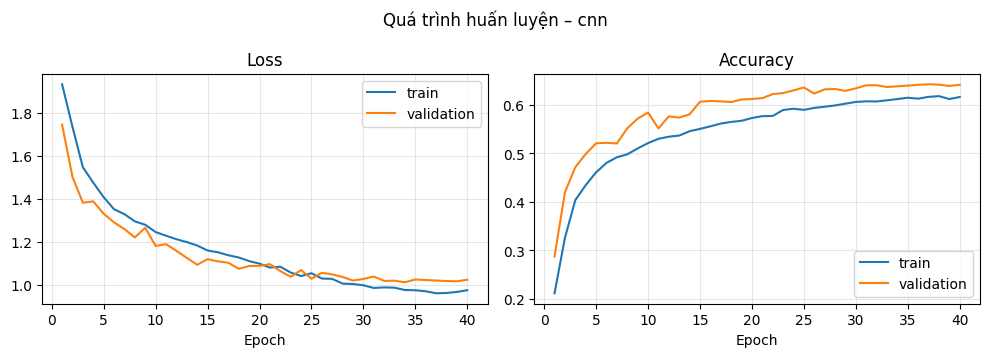

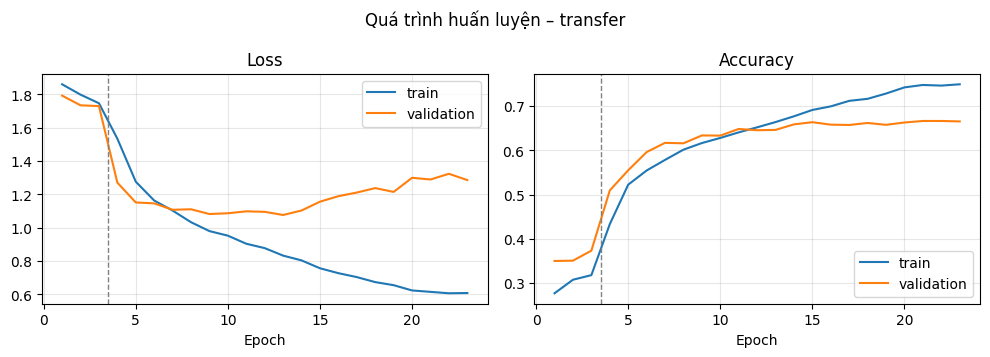

In [12]:
def plot_curves(h, name):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ep = range(1, len(h["val_acc"]) + 1)
    ax[0].plot(ep, h["train_loss"], label="train"); ax[0].plot(ep, h["val_loss"], label="validation"); ax[0].set_title("Loss")
    ax[1].plot(ep, h["train_acc"], label="train"); ax[1].plot(ep, h["val_acc"], label="validation"); ax[1].set_title("Accuracy")
    for a in ax:
        a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=.3)
    if name == "transfer":
        for a in ax:
            a.axvline(EPOCHS_M2_HEAD + .5, color="gray", ls="--", lw=1)   # bắt đầu fine-tune
    fig.suptitle(f"Quá trình huấn luyện – {name}"); fig.tight_layout()
    fig.savefig(OUT_R / f"curves_{name}.png", dpi=150); plt.show()


plot_curves(h1, "cnn"); plot_curves(h2, "transfer")

**Nhận xét M5 – đồ thị huấn luyện.**
- **M1 (40 epoch):** loss giảm đều rồi đi ngang; val loss thấp nhất ở khoảng epoch 34 (≈ 1,01) và val accuracy tốt nhất 0,6423 (xung quanh epoch 37–38).
  Accuracy train (≈ 0,616) thấp hơn validation (≈ 0,641) vì dropout và augmentation chỉ bật ở tập train, còn validation là ảnh nguyên bản; chưa thấy overfit rõ.
- **M2 (3 epoch đóng băng + 20 epoch fine-tune, tổng 23 epoch trong lần chạy này):** giai đoạn đóng băng backbone chỉ đạt validation accuracy ≈ 0,35–0,37 vì chỉ học lớp cuối trên ảnh xám 96×96;
  sau khi mở khoá toàn mạng (đường nét đứt trên đồ thị) độ chính xác tăng nhanh. Val loss thấp nhất ở khoảng epoch 13 (≈ 1,08), val accuracy tốt nhất 0,6663 ở khoảng epoch 21.
  Sau epoch 13, train loss tiếp tục giảm (còn ≈ 0,61) trong khi val loss tăng (lên ≈ 1,29) và khoảng cách train/val mở rộng (accuracy ≈ 0,75 so với ≈ 0,67): đây là dấu hiệu **overfit**.
  Vì checkpoint được chọn theo val accuracy cao nhất nên trọng số lưu lại là của epoch có val accuracy tốt nhất, trước khi overfit nặng hơn.

## 4. Lưu trọng số và kết quả
Checkpoint chứa cả tên lớp và kích thước ảnh vào, nên app không cần cấu hình thêm.

In [13]:
def save_ckpt(model, kind, name):
    torch.save({"kind": kind, "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
                "classes": CLASSES, "img_size": INPUT[kind]}, OUT_W / f"{name}.pt")


save_ckpt(m1, "cnn", "cnn"); save_ckpt(m2, "transfer", "transfer")
results = {"classes": CLASSES, "n_train": len(tr_paths), "n_val": len(va_paths), "n_test": len(te_paths),
           "table": rows, "ablation_m1_class_weight": ablation}
json.dump(results, open(OUT_R / "results.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=float)
print("Đã lưu:", sorted(p.name for p in OUT_W.glob("*.pt")), "và", OUT_R)
print("Colab: tải về weights/*.pt, report_assets/ và notebook đã chạy (File → Download .ipynb).")

Đã lưu: ['cnn.pt', 'transfer.pt'] và /content/CE200292_TranThanhGiaKhang_Lab2/report_assets
Colab: tải về weights/*.pt, report_assets/ và notebook đã chạy (File → Download .ipynb).
